**IMPORT FUNCTION**

In [1]:
# importing required libraries

from datetime import datetime

# Data Handling & Math
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical Transformations
from scipy import stats
from scipy.stats.mstats import winsorize

# Preprocessing & Encoders
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, RobustScaler, StandardScaler
from sklearn.preprocessing import (PowerTransformer)
import re

# Dimensionality Reduction
from sklearn.decomposition import PCA

# Machine Learning Model & Metrics
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
import lightgbm as lgb
from sklearn.model_selection import KFold

# Environment Settings
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

print("ALL REQUIRED LIBRARIES LOADED SUCCESSFULLY")

ALL REQUIRED LIBRARIES LOADED SUCCESSFULLY


**MAPPING DICTIONARIES**

In [2]:
# defining maping dictionaries

# maping dictionaries

# 1. Standard quality map for ordinal features
QUAL_MAP = {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}

# 2. Helper binary map
BINARY_MAP = {'Y': 1, 'N': 0, 'Yes': 1, 'No': 0, 'True': 1, 'False': 0}

print ("all maping dictionaries defined")

all maping dictionaries defined


**HELPER FUNCTIONS**

In [3]:
# defining helper funtions.

# 1. helper funtion to convert boolean strings to numerical hierarchy
def process_binary_feature(df, column_name, fill_na=0):
    """
    Maps binary columns ('Y'/'N', 'Yes'/'No') to 1/0 integers.
    Fills missing values with designated fill_na value (default 0).
    """
    return df[column_name].map(BINARY_MAP).fillna(fill_na).astype(int)

# 2. helper funtion to convert quality strings to numerical hierarchy
def process_ordinal_quality(df, col_name, fill_na='None'):
    """Imputes missing values and applies standard ordinal integer mapping."""
    df[col_name] = df[col_name].fillna(fill_na).map(QUAL_MAP).fillna(0).astype(int)
    return df

# 3. helper function to get dummies 
def process_rare_dummies(df, col_name, keep_categories="all"):
    """Generates dummy variables for a single DataFrame based on specified categories."""
    if keep_categories == "all":
        target_cats = df[col_name].dropna().unique().tolist()
    else:
        target_cats = list(keep_categories)

    # Map unseen values to 'Other'
    df_mapped = df[col_name].apply(
        lambda x: x if x in target_cats else "Other"
    )

    all_expected = list(target_cats)
    if "Other" not in all_expected and (df_mapped == "Other").any():
        all_expected.append("Other")

    # Cast to Categorical and get dummies
    df_cat = pd.Categorical(df_mapped, categories=all_expected)
    dummies = pd.get_dummies(
        df_cat, prefix=col_name, drop_first=False, dtype=int
    )

    # Attach dummies and drop raw column
    return pd.concat([df.drop(columns=[col_name]), dummies], axis=1)

# 4. defining helper function for inspecting the fetures of data frame 

def inspect_column(df, col_name):
    """Prints unique count, unique values, missing value count, and distribution for a column."""
    print(f"=== Summary for: {col_name} ===")
    print(f"Unique Count: {df[col_name].nunique(dropna=False)}")
    print(f"Unique Values: {df[col_name].unique()}")
    print(f"Total Missing Values: {df[col_name].isnull().sum()}")
    print("\nValue Counts (including NaNs):")
    print(df[col_name].value_counts(dropna=False))
    print("=" * 35 + "\n")    

# 5. defining helper function for Plots a boxplot and histogram for continuous numeric features to inspect distributions
# and outliers.

def visualize_numeric(df, col_name):
    """Plots a boxplot and histogram for continuous numeric features to inspect distributions and outliers."""
    fig, (ax_box, ax_hist) = plt.subplots(
        2, 1, figsize=(8, 5), sharex=True, gridspec_kw={'height_ratios': [0.2, 0.8]}
    )
    
    # Upper boxplot for outlier detection
    sns.boxplot(data=df, x=col_name, ax=ax_box, color='skyblue')
    ax_box.set(xlabel='')
    
    # Lower histogram for distribution shape and skewness
    sns.histplot(data=df, x=col_name, kde=True, ax=ax_hist, color='skyblue')
    
    plt.suptitle(f'Distribution & Outliers: {col_name}', fontsize=12)
    plt.tight_layout()
    plt.show()

    print(col_name, " Skewness:", df[col_name].skew())

    

# 6. defining helper function to check category match of 2 same columns from diffrent identical data_set 

def check_category_match(train_df, test_df, col_name):
    """Compares unique values between train and test to ensure category alignment."""
    train_uniques = set(train_df[col_name].dropna().unique())
    test_uniques = set(test_df[col_name].dropna().unique())
    
    match = train_uniques == test_uniques
    print(f"=== Category Match for '{col_name}': {match} ===")
    print(f"Train Unique Categories ({len(train_uniques)}): {train_uniques}")
    print(f"Test Unique Categories  ({len(test_uniques)}): {test_uniques}")
    
    diff = test_uniques - train_uniques
    if diff:
        print(f"⚠️ WARNING: Categories in Test but NOT in Train: {diff}")
    return match

# 7. defining helper function to check category mismatch of 2 same columns from diffrent identical data_set 
    
def check_category_mismatch(train_df, test_df, col_name):
    train_cats = set(train_df[col_name].dropna().unique())
    test_cats = set(test_df[col_name].dropna().unique())

    print(f"--- Mismatch Report for: {col_name} ---")
    print(f"In Train but NOT Test: {train_cats - test_cats or 'None'}")
    print(f"In Test but NOT Train: {test_cats - train_cats or 'None'}\n")


def process_categorical_encoding(df, col_name, mapping_dict=None, fill_na='Missing'):
    """
    Imputes missing values and applies either a provided mapping dictionary 
    or dynamically creates an integer encoding for any categorical column.
    """
    # 1. Fill missing values
    df[col_name] = df[col_name].fillna(fill_na).astype(str)
    
    # 2. Apply mapping if provided, otherwise factorize dynamically
    if mapping_dict is not None:
        df[col_name] = df[col_name].map(mapping_dict).fillna(0).astype(int)
    else:
        # Dynamically map unique values to integers
        df[col_name], unique_vals = pd.factorize(df[col_name])
        
    return df


    

print ("all helper functions defined")

all helper functions defined


**EDA STARTED**

In [4]:
# Load the 2 original files

train = pd.read_csv('course data/python_using_AI_course_data/data_sets/playground-series/train.csv')  # 
test = pd.read_csv('course data/python_using_AI_course_data/data_sets/playground-series/test.csv')    # 

raw_train = train.copy()
raw_test = test.copy()

train.info()
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 188533 entries, 0 to 188532
Data columns (total 13 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   id            188533 non-null  int64 
 1   brand         188533 non-null  object
 2   model         188533 non-null  object
 3   model_year    188533 non-null  int64 
 4   milage        188533 non-null  int64 
 5   fuel_type     183450 non-null  object
 6   engine        188533 non-null  object
 7   transmission  188533 non-null  object
 8   ext_col       188533 non-null  object
 9   int_col       188533 non-null  object
 10  accident      186081 non-null  object
 11  clean_title   167114 non-null  object
 12  price         188533 non-null  int64 
dtypes: int64(4), object(9)
memory usage: 18.7+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125690 entries, 0 to 125689
Data columns (total 12 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ---

In [5]:
# 1. Separate SalePrice temporarily to compare feature columns

train_features = [col for col in train.columns if col != 'price']
test_features = list(test.columns)

In [6]:
# 1. Columns present in TRAIN but missing in TEST
train_only = set(train_features) - set(test_features)

# 2. Columns present in TEST but missing in TRAIN
test_only = set(test_features) - set(train_features)

# 3. Check if counts match but order is different
same_columns_different_order = (set(train_features) == set(test_features)) and (train_features != test_features)

print("Columns in Train but NOT in Test:", train_only)
print("Columns in Test but NOT in Train:", test_only)
print("Is column ORDER the only issue?:", same_columns_different_order)

Columns in Train but NOT in Test: set()
Columns in Test but NOT in Train: set()
Is column ORDER the only issue?: False


In [7]:
# 1   brand         object

inspect_column(train, 'brand')
inspect_column(test, 'brand')

check_category_mismatch(train, test, 'brand')


=== Summary for: brand ===
Unique Count: 57
Unique Values: ['MINI' 'Lincoln' 'Chevrolet' 'Genesis' 'Mercedes-Benz' 'Audi' 'Ford'
 'BMW' 'Tesla' 'Cadillac' 'Land' 'GMC' 'Toyota' 'Hyundai' 'Volvo'
 'Volkswagen' 'Buick' 'Rivian' 'RAM' 'Hummer' 'Alfa' 'INFINITI' 'Jeep'
 'Porsche' 'McLaren' 'Honda' 'Lexus' 'Dodge' 'Nissan' 'Jaguar' 'Acura'
 'Kia' 'Mitsubishi' 'Rolls-Royce' 'Maserati' 'Pontiac' 'Saturn' 'Bentley'
 'Mazda' 'Subaru' 'Ferrari' 'Aston' 'Lamborghini' 'Chrysler' 'Lucid'
 'Lotus' 'Scion' 'smart' 'Karma' 'Plymouth' 'Suzuki' 'FIAT' 'Saab'
 'Bugatti' 'Mercury' 'Polestar' 'Maybach']
Total Missing Values: 0

Value Counts (including NaNs):
brand
Ford             23088
Mercedes-Benz    19172
BMW              17028
Chevrolet        16335
Audi             10887
Porsche          10612
Land              9525
Toyota            8850
Lexus             8643
Jeep              6474
Cadillac          4674
RAM               4249
Nissan            3930
Tesla             3738
INFINITI          3276
GMC

**Observation:** One hot encoding will create a lot of dummy columns. 

**Plan:** Advised to use categorical encoding.

In [8]:
# 2   model         object

inspect_column(train, 'model')
inspect_column(test, 'model')

check_category_mismatch(train, test, 'model')

=== Summary for: model ===
Unique Count: 1897
Unique Values: ['Cooper S Base' 'LS V8' 'Silverado 2500 LT' ... 'e-Golf SE'
 'Integra w/A-Spec Tech Package' 'IONIQ Plug-In Hybrid SEL']
Total Missing Values: 0

Value Counts (including NaNs):
model
F-150 XLT                        2945
M3 Base                          2229
Camaro 2SS                       1709
M4 Base                          1622
Mustang GT Premium               1526
                                 ... 
IONIQ Plug-In Hybrid SEL            2
X5 3.0i                             1
X5 xDrive40e                        1
XLR Base                            1
Integra w/A-Spec Tech Package       1
Name: count, Length: 1897, dtype: int64

=== Summary for: model ===
Unique Count: 1891
Unique Values: ['Rover LR2 Base' 'Rover Defender SE' 'Expedition Limited' ...
 'X5 xDrive40e' 'X5 3.0si' 'Countryman Cooper']
Total Missing Values: 0

Value Counts (including NaNs):
model
F-150 XLT                      1923
M3 Base                   

**Observation:** neat clean full data with only one issue that a model is unseen for test data.

**Plan:** handle the unseen data using the change of type to category and the our light bgm model can handle it gracfully

=== Summary for: model_year ===
Unique Count: 34
Unique Values: [2007 2002 2017 2021 2018 2016 2020 2015 2011 2013 2023 2019 2012 2014
 2008 2009 2022 2003 2005 2001 2006 2000 2010 2004 1997 1998 1999 1994
 1993 1996 1995 2024 1974 1992]
Total Missing Values: 0

Value Counts (including NaNs):
model_year
2021    18198
2018    16414
2020    15848
2022    15749
2019    15409
2016    13696
2017    12794
2015    11389
2023     8769
2014     8415
2013     6796
2011     6265
2012     6095
2008     5156
2007     4876
2010     4235
2005     3129
2006     2814
2009     2716
2004     2570
2003     1906
2001     1534
2002     1282
2000      558
1999      554
1998      343
1997      312
1996      189
2024      162
1993      140
1995      102
1994       92
1992       14
1974       12
Name: count, dtype: int64

=== Summary for: model_year ===
Unique Count: 36
Unique Values: [2015 2020 2022 2016 2018 2013 2008 2019 2017 2002 2023 2014 2021 2012
 2004 2009 2011 2010 2001 2007 2005 2000 2003 2006 1999 2

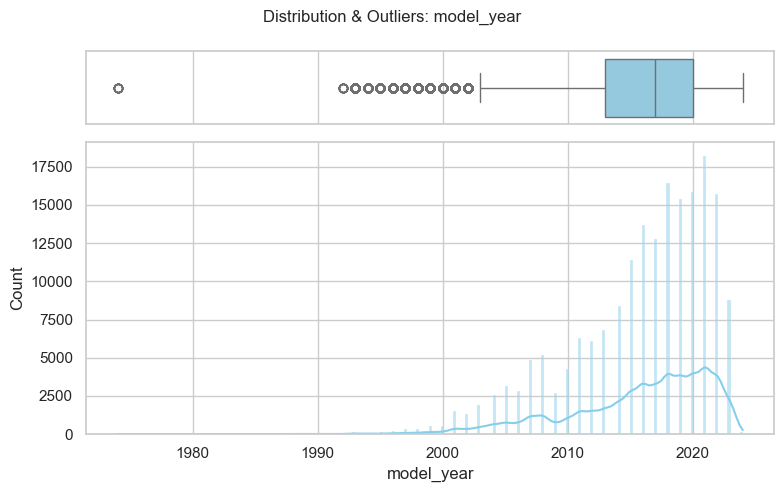

model_year  Skewness: -1.044511173534806


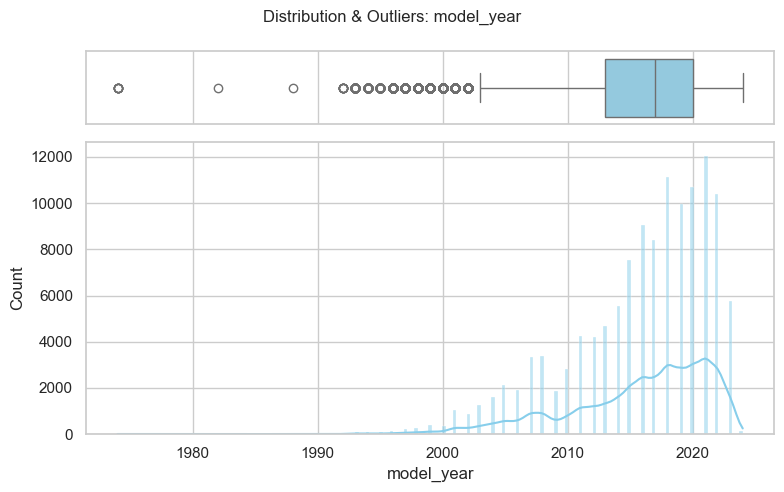

model_year  Skewness: -1.03648857555472
train model_year Skewness: -1.044511173534806
test model_year Skewness: -1.03648857555472


In [9]:
# 3   model_year    int64 

inspect_column(train, 'model_year')
inspect_column(test, 'model_year')



visualize_numeric(train,'model_year')
visualize_numeric(test, 'model_year')

print("train model_year Skewness:", train['model_year'].skew())
print("test model_year Skewness:", test['model_year'].skew())

**Observation:** highly skewed data but we can generate good things from this

**Plan:** create a new feature of car age which is pure running numeric feature will help our model using 2026 as our base timeline using formula (2026 - 'model_year').

=== Summary for: milage ===
Unique Count: 6651
Unique Values: [213000 143250 136731 ...   4721   2922 134603]
Total Missing Values: 0

Value Counts (including NaNs):
milage
60000     1319
170000    1246
120000    1178
110000    1155
130000     970
          ... 
5111         1
29755        1
28761        1
170612       1
134603       1
Name: count, Length: 6651, dtype: int64

=== Summary for: milage ===
Unique Count: 5700
Unique Values: [ 98000   9142  28121 ... 171681  95401  21436]
Total Missing Values: 0

Value Counts (including NaNs):
milage
170000    919
60000     863
110000    763
120000    742
130000    664
         ... 
83859       1
125565      1
4821        1
232681      1
21436       1
Name: count, Length: 5700, dtype: int64



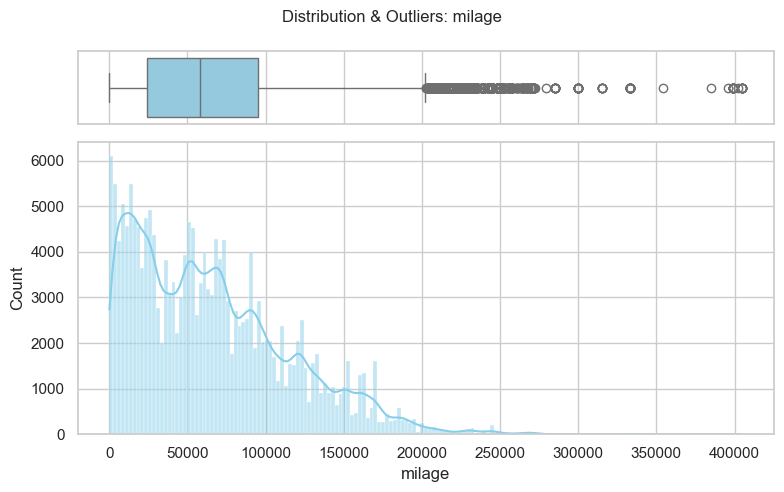

milage  Skewness: 0.8950620098363099


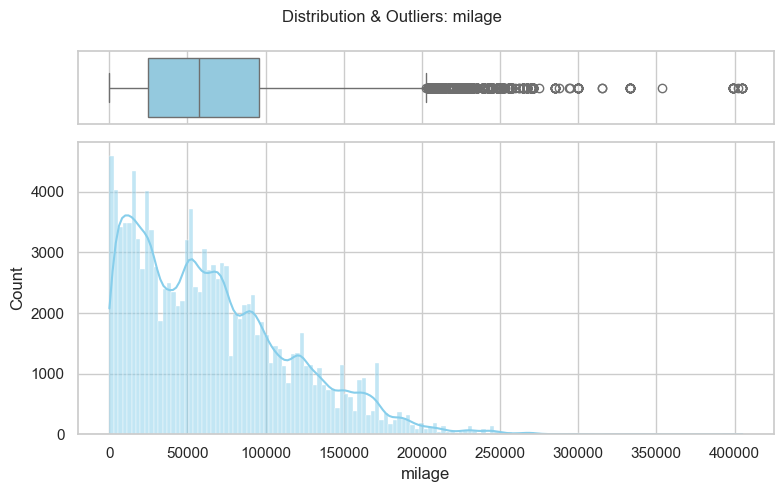

milage  Skewness: 0.9099278163459368
train milage Skewness: 0.8950620098363099
test milage Skewness: 0.9099278163459368


In [10]:
# 4   milage        int64 

inspect_column(train, 'milage')
inspect_column(test, 'milage')

visualize_numeric(train, 'milage')
visualize_numeric(test, 'milage')

print("train milage Skewness:", train['milage'].skew())
print("test milage Skewness:", test['milage'].skew())

**Observation:**  skewed but in mangeable position.

**Plan:** pass on as it is cause the milage can help us depriciation so decided not to clip.

In [11]:
# 5   fuel_type     object

inspect_column(train, 'fuel_type')
inspect_column(test, 'fuel_type')


=== Summary for: fuel_type ===
Unique Count: 8
Unique Values: ['Gasoline' 'E85 Flex Fuel' nan 'Hybrid' 'Diesel' 'Plug-In Hybrid' '–'
 'not supported']
Total Missing Values: 5083

Value Counts (including NaNs):
fuel_type
Gasoline          165940
Hybrid              6832
E85 Flex Fuel       5406
NaN                 5083
Diesel              3955
–                    781
Plug-In Hybrid       521
not supported         15
Name: count, dtype: int64

=== Summary for: fuel_type ===
Unique Count: 8
Unique Values: ['Gasoline' 'Hybrid' 'Diesel' 'E85 Flex Fuel' nan 'Plug-In Hybrid' '–'
 'not supported']
Total Missing Values: 3383

Value Counts (including NaNs):
fuel_type
Gasoline          110533
Hybrid              4676
E85 Flex Fuel       3523
NaN                 3383
Diesel              2686
–                    538
Plug-In Hybrid       337
not supported         14
Name: count, dtype: int64



**Observation:** lot of missing and unknown values 

**Plan:** impute all nan, -, not supported to unknown than pass it as categorical data type.

In [12]:
# 6   engine        object

inspect_column(train, 'engine')
inspect_column(test, 'engine')


=== Summary for: engine ===
Unique Count: 1117
Unique Values: ['172.0HP 1.6L 4 Cylinder Engine Gasoline Fuel'
 '252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel'
 '320.0HP 5.3L 8 Cylinder Engine Flex Fuel Capability' ...
 '78.0HP 1.2L 3 Cylinder Engine Gasoline Fuel'
 '139.0HP 1.6L 4 Cylinder Engine Plug-In Electric/Gas'
 '313.0HP 2.0L 4 Cylinder Engine Plug-In Electric/Gas']
Total Missing Values: 0

Value Counts (including NaNs):
engine
355.0HP 5.3L 8 Cylinder Engine Gasoline Fuel           3462
240.0HP 2.0L 4 Cylinder Engine Gasoline Fuel           2902
420.0HP 6.2L 8 Cylinder Engine Gasoline Fuel           2841
2.0L I4 16V GDI DOHC Turbo                             2680
375.0HP 3.5L V6 Cylinder Engine Gasoline Fuel          2451
                                                       ... 
151.0HP 1.5L 4 Cylinder Engine Gas/Electric Hybrid        1
184.0HP 2.4L 4 Cylinder Engine Flex Fuel Capability       1
78.0HP 1.2L 3 Cylinder Engine Gasoline Fuel               1
139.0HP 1.6L 4 Cylinde

**Observation:** neatly clean data

**Plan:** pass it with only change the data type to categorical 

In [13]:
# 7   transmission  object

inspect_column(train, 'transmission')
inspect_column(test, 'transmission')

check_category_mismatch(train, test, 'transmission')

=== Summary for: transmission ===
Unique Count: 52
Unique Values: ['A/T' 'Transmission w/Dual Shift Mode' '7-Speed A/T' '8-Speed A/T'
 '10-Speed Automatic' '1-Speed A/T' '6-Speed A/T' '10-Speed A/T'
 '9-Speed A/T' '8-Speed Automatic' '9-Speed Automatic' '5-Speed A/T'
 'Automatic' '7-Speed Automatic with Auto-Shift' 'CVT Transmission'
 '5-Speed M/T' 'M/T' '6-Speed M/T' '6-Speed Automatic' '4-Speed Automatic'
 '7-Speed M/T' '2-Speed A/T' '1-Speed Automatic' 'Automatic CVT'
 '4-Speed A/T' '6-Speed Manual' 'Transmission Overdrive Switch'
 '8-Speed Automatic with Auto-Shift' '7-Speed Manual' '7-Speed Automatic'
 '9-Speed Automatic with Auto-Shift' '6-Speed Automatic with Auto-Shift'
 '6-Speed Electronically Controlled Automatic with O' 'F' 'CVT-F'
 '8-Speed Manual' 'Manual' '–' '2' '6 Speed At/Mt' '5-Speed Automatic'
 '2-Speed Automatic' '8-SPEED A/T' '7-Speed' 'Variable'
 'Single-Speed Fixed Gear' '8-SPEED AT'
 '10-Speed Automatic with Overdrive' '7-Speed DCT Automatic'
 'SCHEDULED FOR OR 

**Observation:** data is complete but case sensitivity is found 

**Plan:** pass it as it is only chage the data type to categorical cause matching all theese 52 unique vaues into shorter
          list can create a lo of hassel 

In [14]:
# 8   ext_col       object

inspect_column(train, 'ext_col')
inspect_column(test, 'ext_col')

check_category_mismatch(train, test, 'ext_col')


=== Summary for: ext_col ===
Unique Count: 319
Unique Values: ['Yellow' 'Silver' 'Blue' 'Black' 'White' 'Snowflake White Pearl Metallic'
 'Gray' 'Green' 'Santorini Black Metallic' 'Purple'
 'Ebony Twilight Metallic' 'Red' 'Magnetite Black Metallic'
 'Diamond Black' 'Vega Blue' 'Beige' 'Gold' 'Platinum White Pearl'
 'Metallic' 'White Frost Tri-Coat' 'Firecracker Red Clearcoat'
 'Phytonic Blue Metallic' 'Blu' 'Orange' 'Brown'
 'Brilliant Silver Metallic' 'Black Raven' 'Black Clearcoat' 'Firenze Red'
 'Agate Black Metallic' 'Glacial White Pearl' 'Majestic Plum Metallic'
 'designo Diamond White Metallic' 'Oxford White' 'Black Sapphire Metallic'
 'Mythos Black' 'Granite Crystal Clearcoat Metallic'
 'White Diamond Tri-Coat' 'Magnetite Gray Metallic'
 'Carpathian Grey Premium Metallic' 'designo Diamond White Bright'
 'Phantom Black Pearl Effect / Black Roof' 'Nebula Gray Pearl'
 'Deep Crystal Blue Mica' 'Flame Red Clearcoat' 'Lunar Blue Metallic'
 'Bright White Clearcoat' 'Rapid Red Metallic 

**Observation:**  complete data.

**Plan:** only data type change to categorical advised.

In [15]:
# 9   int_col       object

inspect_column(train, 'int_col')
inspect_column(test, 'int_col')

check_category_mismatch(train, test, 'int_col')


=== Summary for: int_col ===
Unique Count: 156
Unique Values: ['Gray' 'Beige' 'Black' '–' 'Blue' 'White' 'Red' 'Brown' 'Dark Galvanized'
 'Parchment.' 'Boulder' 'Orange' 'Medium Earth Gray' 'Ebony'
 'Canberra Beige' 'Jet Black' 'Silver' 'Light Platinum / Jet Black'
 'Macchiato/Magmagrey' 'Gold' 'Cloud' 'Rioja Red' 'Global Black' 'Green'
 'Medium Stone' 'Navy Pier' 'Dark Ash' 'BLACK' 'Portland' 'Sandstone'
 'Canberra Beige/Black' 'Diesel Gray / Black' 'Sarder Brown' 'Black Onyx'
 'White / Brown' 'Black/Gun Metal' 'Slate' 'Satin Black'
 'Macchiato Beige/Black' 'Charcoal' 'Black / Express Red' 'Cappuccino'
 'Aragon Brown' 'Parchment' 'Oyster W/Contrast' 'Adrenaline Red' 'Ebony.'
 'Shara Beige' 'Graystone' 'Pearl Beige' 'Nero Ade' 'Graphite'
 'Tan/Ebony/Ebony' 'Charcoal Black' 'Medium Ash Gray' 'Ebony Black'
 'Light Titanium' 'Sakhir Orange' 'Tan' 'Rock Gray' 'Brandy'
 'Carbon Black' 'Amber' 'Black w/Red Stitching' 'Hotspur' 'Chateau' 'Ice'
 'Deep Garnet' 'Blk' 'Grace White' 'Oyster/Black'

**Observation:** complete data.

**Plan:** only data type change to categorical advised.

In [16]:
# 10  accident      object

inspect_column(train, 'accident')
inspect_column(test, 'accident')

check_category_mismatch(train, test, 'accident')


=== Summary for: accident ===
Unique Count: 3
Unique Values: ['None reported' 'At least 1 accident or damage reported' nan]
Total Missing Values: 2452

Value Counts (including NaNs):
accident
None reported                             144514
At least 1 accident or damage reported     41567
NaN                                         2452
Name: count, dtype: int64

=== Summary for: accident ===
Unique Count: 3
Unique Values: ['None reported' 'At least 1 accident or damage reported' nan]
Total Missing Values: 1632

Value Counts (including NaNs):
accident
None reported                             96263
At least 1 accident or damage reported    27795
NaN                                        1632
Name: count, dtype: int64

--- Mismatch Report for: accident ---
In Train but NOT Test: None
In Test but NOT Train: None



**Observation:** lot of missing values.

**Plan:** impute nan with unknown than change the data type to cvategorical advised

In [17]:
# 11  clean_title   object

inspect_column(train, 'clean_title')
inspect_column(test, 'clean_title')

check_category_mismatch(train, test, 'clean_title')


=== Summary for: clean_title ===
Unique Count: 2
Unique Values: ['Yes' nan]
Total Missing Values: 21419

Value Counts (including NaNs):
clean_title
Yes    167114
NaN     21419
Name: count, dtype: int64

=== Summary for: clean_title ===
Unique Count: 2
Unique Values: ['Yes' nan]
Total Missing Values: 14239

Value Counts (including NaNs):
clean_title
Yes    111451
NaN     14239
Name: count, dtype: int64

--- Mismatch Report for: clean_title ---
In Train but NOT Test: None
In Test but NOT Train: None



**Observation:** lot of missing values.

**Plan:** impute nan as unknown change data type to categorical advised.

In [18]:
print ("EDA completed")

EDA completed


**PROCESSING START**

In [19]:
# 1   brand         object

# changing the data type to categoricl form.

process_categorical_encoding(train , 'brand', mapping_dict=None, fill_na='Missing')
process_categorical_encoding(test , 'brand', mapping_dict=None, fill_na='Missing')

print ("1st cloumn processed")    

1st cloumn processed


In [20]:
# 2   model         object

process_categorical_encoding(train , 'model', mapping_dict=None, fill_na='Missing')
process_categorical_encoding(test , 'model', mapping_dict=None, fill_na='Missing')

print ("2nd cloumn processed")

2nd cloumn processed


In [21]:
# 3   model_year    int64 

train['car_age'] = 2026- train['model_year']
test['car_age'] = 2026 - test['model_year']

print ("3rd column processed")

3rd column processed


In [22]:
# 4   milage        int64 

print ("4th column processed")

4th column processed


In [23]:
# 5   fuel_type     object

# 1. Fill missing values (NaN) and common placeholder artifacts with 'unknown'
train['fuel_type'] = train['fuel_type'].fillna('unknown').replace({'-': 'unknown', 'not_supported': 'unknown'}).astype(
    'category')
test['fuel_type'] = test['fuel_type'].fillna('unknown').replace({'-': 'unknown', 'not_supported': 'unknown'}).astype(
    'category')


print("5th column processed")

5th column processed


In [24]:
# 6   engine        object

train['engine'] = train['engine'].astype('category')
test['engine'] = test['engine'].astype('category')

print ("6th column processed")

6th column processed


In [25]:
# 7   transmission  object

train['transmission'] = train['transmission'].astype('category')
test['transmission'] = test['transmission'].astype('category')

print ("7th column processed")

7th column processed


In [26]:
# 8   ext_col       object

train['ext_col'] = train['ext_col'].astype('category')
test['ext_col'] = test['ext_col'].astype('category')

print ("8th column processed")

8th column processed


In [27]:
# 9   int_col       object

train['int_col'] = train['int_col'].astype('category')
test['int_col'] = test['int_col'].astype('category')

print ("9th column processed")

9th column processed


In [28]:
# 10  accident      object

train['accident'] = train['accident'].fillna('unknown').astype('category')
test['accident'] = test['accident'].fillna('unknown').astype('category')

print ("10th column processed")

10th column processed


In [29]:
# 11  clean_title   object

train['clean_title'] = train['clean_title'].fillna('unknown').astype('category')
test['clean_title'] = test['clean_title'].fillna('unknown').astype('category')

print ("11th column processed")

11th column processed


In [30]:
# Drop model_year since car_age captures the exact same information

train = train.drop(columns=['model_year'])
test = test.drop(columns=['model_year'])

In [31]:
# Let's combine train and test temporarily to calculate global or group statistics safely, 
# or compute them strictly out-of-fold to prevent data leakage.
# For a robust approach, let's create group-based price aggregations based on train data:

# 1. Brand-level pricing pattern (median and mean price per brand)
brand_stats = train.groupby('brand')['price'].agg(['mean', 'median', 'std']).reset_index()
brand_stats.columns = ['brand', 'brand_mean_price', 'brand_median_price', 'brand_std_price']

# 2. Nested Grouping: Brand + Model pricing pattern
# (Captures how a specific model within a brand dictates price)
model_stats = train.groupby(['brand', 'model'])['price'].agg(['mean', 'median']).reset_index()
model_stats.columns = ['brand', 'model', 'model_mean_price', 'model_median_price']

# Merge these patterns back into your train and test sets
train = train.merge(brand_stats, on='brand', how='left')
test = test.merge(brand_stats, on='brand', how='left')

train = train.merge(model_stats, on=['brand', 'model'], how='left')
test = test.merge(model_stats, on=['brand', 'model'], how='left')

# 3. Code the Usage / Depreciation Calculator (Mileage Intensity)
# (Assumes 'milage' and 'car_age' columns exist in your dataset)
train['mileage_per_year'] = train['milage'] / (train['car_age'] + 1)
test['mileage_per_year'] = test['milage'] / (test['car_age'] + 1)

print("Nested grouping and calculator features generated successfully!")

Nested grouping and calculator features generated successfully!


In [32]:
# 1. Identify text/categorical columns and convert them to 'category' dtype
categorical_cols = ['brand', 'model', 'engine', 'transmission', 'ext_col', 'int_col', 'fuel_type', 'accident', 'clean_title']

for col in categorical_cols:
    if col in train.columns:
        train[col] = train[col].astype('category')
        test[col] = test[col].astype('category')


In [33]:
# Check target summary stats to spot extreme outliers
print(train['price'].describe())

# Check a sample of messy engine descriptions
print("\nSample Engine Strings:")
print(train['engine'].head(10))

count    1.885330e+05
mean     4.387802e+04
std      7.881952e+04
min      2.000000e+03
25%      1.700000e+04
50%      3.082500e+04
75%      4.990000e+04
max      2.954083e+06
Name: price, dtype: float64

Sample Engine Strings:
0         172.0HP 1.6L 4 Cylinder Engine Gasoline Fuel
1         252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel
2    320.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...
3         420.0HP 5.0L 8 Cylinder Engine Gasoline Fuel
4         208.0HP 2.0L 4 Cylinder Engine Gasoline Fuel
5         252.0HP 2.0L 4 Cylinder Engine Gasoline Fuel
6        333.0HP 3.0L V6 Cylinder Engine Gasoline Fuel
7    355.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...
8                      2.7L V6 24V PDI DOHC Twin Turbo
9    425.0HP 3.0L Straight 6 Cylinder Engine Gasoli...
Name: engine, dtype: category
Categories (1117, object): ['1.2L I3 12V GDI DOHC Turbo', '1.3L I3 12V GDI DOHC Turbo', '1.3L I3 12V MPFI DOHC Turbo', '1.4L I4 16V GDI DOHC Turbo', ..., 'Standard Range Battery', 'V6', 'V8', 

In [34]:
# 1. Define target and features (Splitting X and y from train)
target_col = 'price'
drop_cols = ['id', target_col]

# Calculate the 99th percentile threshold for price
price_cap = train['price'].quantile(0.99)
print(f"Clipping prices above 99th percentile: ${price_cap:,.2f}")

# Filter out extreme outliers from the training data
train_filtered = train[train['price'] <= price_cap].copy()

# Re-run your X and y split on the filtered dataset
X_filtered = train_filtered.drop(columns=[col for col in drop_cols if col in train_filtered.columns])
y_filtered_log = np.log1p(train_filtered[target_col])

# Re-run your validation loop on X_filtered...

Clipping prices above 99th percentile: $259,500.00


In [35]:
# 1. Parse Engine Strings into Clean Numerical Features
def parse_engine(df):
    # Extract Horsepower (e.g., '172.0HP' -> 172.0)
    df['engine_hp'] = df['engine'].str.extract(r'([\d.]+)\s*HP', flags=re.IGNORECASE).astype(float)
    
    # Extract Liters / Displacement (e.g., '1.6L' -> 1.6)
    df['engine_liters'] = df['engine'].str.extract(r'([\d.]+)\s*L', flags=re.IGNORECASE).astype(float)
    
    # Extract Cylinder Count (e.g., '4 Cylinder' or 'V8' -> 4, 8)
    df['engine_cylinders'] = df['engine'].str.extract(r'(\d+)\s*(?:Cylinder|Cyl)', flags=re.IGNORECASE).astype(float)
    
    # Extract Turbo / Twin Turbo binary flag
    df['is_turbo'] = df['engine'].str.contains('turbo', case=False, na=False).astype(int)
    
    return df

train = parse_engine(train)
test = parse_engine(test)

# Fill any missing values from parsing with median/zero
for col in ['engine_hp', 'engine_liters', 'engine_cylinders']:
    train[col] = train[col].fillna(train[col].median())
    test[col] = test[col].fillna(train[col].median())

print("Engine features successfully parsed into numbers!")

Engine features successfully parsed into numbers!


In [36]:
# Select only numeric columns for correlation
numeric_df = train.select_dtypes(include=['number'])
corr_matrix = numeric_df.corr()

# Display Audit Summary
print("==================================================")
print(f" FULL FEATURE CORRELATION AUDIT")
print(f" Total Features Evaluated: {len(corr_matrix)}")
print("==================================================\n")

# Configure pandas to print ALL rows without truncation
pd.set_option('display.max_rows', None)

print("--- Full Ranked Correlation with Price ---")
print(corr_matrix)

# Reset pandas view setting back to default after printing
pd.reset_option('display.max_rows')

 FULL FEATURE CORRELATION AUDIT
 Total Features Evaluated: 14

--- Full Ranked Correlation with Price ---
                          id    milage     price   car_age  brand_mean_price  \
id                  1.000000 -0.001834 -0.000877 -0.000076         -0.000062   
milage             -0.001834  1.000000 -0.283067  0.669936         -0.250306   
price              -0.000877 -0.283067  1.000000 -0.231795          0.213601   
car_age            -0.000076  0.669936 -0.231795  1.000000         -0.160610   
brand_mean_price   -0.000062 -0.250306  0.213601 -0.160610          1.000000   
brand_median_price  0.001140 -0.271207  0.204835 -0.208542          0.958962   
brand_std_price    -0.001413 -0.155607  0.168727 -0.097818          0.789917   
model_mean_price    0.000896 -0.479827  0.353373 -0.438583          0.604463   
model_median_price -0.000554 -0.508828  0.331211 -0.509275          0.554900   
mileage_per_year   -0.002564  0.755887 -0.212366  0.147226         -0.211346   
engine_hp     

In [37]:
# 1. Separate SalePrice temporarily to compare feature columns
train_features = [col for col in train.columns if col != 'price']
test_features = list(test.columns)

# 2. Assert shape and column alignment
assert train_features == test_features, "Column mismatch detected between train and test!"
assert len(train_features) == len(test_features), "Feature count mismatch!"

print(f"Validation Passed: Features align perfectly across {len(train_features)} columns!")





Validation Passed: Features align perfectly across 22 columns!


In [38]:
# 1. Columns present in TRAIN but missing in TEST
train_only = set(train_features) - set(test_features)

# 2. Columns present in TEST but missing in TRAIN
test_only = set(test_features) - set(train_features)

# 3. Check if counts match but order is different
same_columns_different_order = (set(train_features) == set(test_features)) and (train_features != test_features)

print("Columns in Train but NOT in Test:", train_only)
print("Columns in Test but NOT in Train:", test_only)
print("Is column ORDER the only issue?:", same_columns_different_order)

Columns in Train but NOT in Test: set()
Columns in Test but NOT in Train: set()
Is column ORDER the only issue?: False


**MODEL TRAIN TEST AND SUBMISSION FILE CREATION**

In [40]:
# 1. Define target and features (Splitting X and y from train)
target_col = 'price'
drop_cols = ['id', target_col]

X = train.drop(columns=[col for col in drop_cols if col in train.columns])
y = train[target_col]
X_test = test.drop(columns=[col for col in ['id', target_col] if col in test.columns])

# 2. Set up K-Fold Cross-Validation
n_splits = 5
kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

# Arrays to store predictions
oof_preds = np.zeros(len(train))
test_preds = np.zeros(len(test))

# 3. Training Loop with explicit RMSE tracking
for fold, (train_idx, val_idx) in enumerate(kf.split(X, y)):
    print(f"--- Training Fold {fold + 1}/{n_splits} ---")
    
    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
    
    model = lgb.LGBMRegressor(
        objective='regression',
        metric='rmse',
        n_estimators=2000,
        learning_rate=0.03,
        random_state=42,
        n_jobs=-1
    )
    
    model.fit(
        X_tr, y_tr,
        eval_set=[(X_val, y_val)],
        eval_metric='rmse',
        callbacks=[lgb.early_stopping(stopping_rounds=100, verbose=False)]
    )
    
    oof_preds[val_idx] = model.predict(X_val)
    test_preds += model.predict(X_test) / n_splits

# 4. Final Evaluation
oof_rmse = np.sqrt(np.mean((y - oof_preds) ** 2))
print(f"\nOverall OOF RMSE: {oof_rmse:.4f}")

--- Training Fold 1/5 ---
[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.017797 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4636
[LightGBM] [Info] Number of data points in the train set: 150826, number of used features: 21
[LightGBM] [Info] Start training from score 43890.785316
--- Training Fold 2/5 ---
[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.011815 seconds.
You can set `force_col_wise=true` t

In [41]:
# Create submission dataframe using the test set's id column and our averaged test predictions
submission = pd.DataFrame({
    'id': test['id'],         # Make sure your test 'id' column name matches your dataset
    'price': test_preds
})

# Save to CSV file for Kaggle upload
submission.to_csv('course data/python_using_AI_course_data/data_sets/playground-series/submission_baseline.csv', index=False)
print("Submission file 'submission_baseline.csv' created successfully!")

Submission file 'submission_baseline.csv' created successfully!
